Bike Rental Demand Prediction


Objective: Download and explore the UCI Bike Sharing dataset using Pandas. Inspect the dataset's rows, columns, data types, and statistical properties before preparing it for machine learning.


In [1]:
import zipfile

with zipfile.ZipFile("/content/bike+sharing+dataset.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [2]:
import os

os.listdir("/content")

['.config',
 'day.csv',
 'bike+sharing+dataset.zip',
 'hour.csv',
 'Readme.txt',
 'sample_data']

In [3]:
import pandas as pd

df = pd.read_csv("/content/hour.csv")

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())
df.info()

Dataset shape: (17379, 17)
Total rows: 17379
Total columns: 17
Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-nu

In [5]:
df.describe()


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [6]:


df.isnull().sum()

print("Duplicate rows:", df.duplicated().sum())


df["dteday"] = pd.to_datetime(df["dteday"])

print("Date column type:", df["dteday"].dtype)

df["day"] = df["dteday"].dt.day
df["month"] = df["dteday"].dt.month
df["dayofweek"] = df["dteday"].dt.dayofweek

df[["dteday", "hr", "day", "month", "dayofweek"]].head()


print("Season values:", sorted(df["season"].unique()))
print("Weather values:", sorted(df["weathersit"].unique()))
print("Holiday values:", sorted(df["holiday"].unique()))
print("Working day values:", sorted(df["workingday"].unique()))


df = pd.get_dummies(
    df,
    columns=["season", "weathersit"],
    dtype=int
)

df.head()


Duplicate rows: 0
Date column type: datetime64[ns]
Season values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Weather values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Holiday values: [np.int64(0), np.int64(1)]
Working day values: [np.int64(0), np.int64(1)]


,instant,dteday,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,...,month,dayofweek,season_1,season_2,season_3,season_4,weathersit_1,weathersit_2,weathersit_3,weathersit_4
0,1,2011-01-01,0,1,0,0,6,0,0.24,0.2879,...,1,5,1,0,0,0,1,0,0,0
1,2,2011-01-01,0,1,1,0,6,0,0.22,0.2727,...,1,5,1,0,0,0,1,0,0,0
2,3,2011-01-01,0,1,2,0,6,0,0.22,0.2727,...,1,5,1,0,0,0,1,0,0,0
3,4,2011-01-01,0,1,3,0,6,0,0.24,0.2879,...,1,5,1,0,0,0,1,0,0,0
4,5,2011-01-01,0,1,4,0,6,0,0.24,0.2879,...,1,5,1,0,0,0,1,0,0,0


In [7]:
print("Missing values:", df.isnull().sum().sum())
print("Dataset shape:", df.shape)

Missing values: 0
Dataset shape: (17379, 26)


In [8]:
df_clean = df.drop(
    columns=["instant", "dteday", "casual", "registered"]
)

print("Final dataset shape:", df_clean.shape)
df_clean.head()

Final dataset shape: (17379, 22)


,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,...,month,dayofweek,season_1,season_2,season_3,season_4,weathersit_1,weathersit_2,weathersit_3,weathersit_4
0,0,1,0,0,6,0,0.24,0.2879,0.81,0.0,...,1,5,1,0,0,0,1,0,0,0
1,0,1,1,0,6,0,0.22,0.2727,0.80,0.0,...,1,5,1,0,0,0,1,0,0,0
2,0,1,2,0,6,0,0.22,0.2727,0.80,0.0,...,1,5,1,0,0,0,1,0,0,0
3,0,1,3,0,6,0,0.24,0.2879,0.75,0.0,...,1,5,1,0,0,0,1,0,0,0
4,0,1,4,0,6,0,0.24,0.2879,0.75,0.0,...,1,5,1,0,0,0,1,0,0,0


In [9]:
df_clean = df_clean.drop(columns=["month"])

print("Final dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Target column present:", "cnt" in df_clean.columns)

df_clean.head()

Final dataset shape: (17379, 21)
Missing values: 0
Target column present: True


,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,...,day,dayofweek,season_1,season_2,season_3,season_4,weathersit_1,weathersit_2,weathersit_3,weathersit_4
0,0,1,0,0,6,0,0.24,0.2879,0.81,0.0,...,1,5,1,0,0,0,1,0,0,0
1,0,1,1,0,6,0,0.22,0.2727,0.80,0.0,...,1,5,1,0,0,0,1,0,0,0
2,0,1,2,0,6,0,0.22,0.2727,0.80,0.0,...,1,5,1,0,0,0,1,0,0,0
3,0,1,3,0,6,0,0.24,0.2879,0.75,0.0,...,1,5,1,0,0,0,1,0,0,0
4,0,1,4,0,6,0,0.24,0.2879,0.75,0.0,...,1,5,1,0,0,0,1,0,0,0


In [10]:
print("Dataset shape:", df_clean.shape)
print("\nMissing values:", df_clean.isnull().sum().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())
print("\nColumn names:")
print(df_clean.columns.tolist())

df_clean.info()

Dataset shape: (17379, 21)

Missing values: 0

Duplicate rows: 0

Column names:
['yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'day', 'dayofweek', 'season_1', 'season_2', 'season_3', 'season_4', 'weathersit_1', 'weathersit_2', 'weathersit_3', 'weathersit_4']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   yr            17379 non-null  int64  
 1   mnth          17379 non-null  int64  
 2   hr            17379 non-null  int64  
 3   holiday       17379 non-null  int64  
 4   weekday       17379 non-null  int64  
 5   workingday    17379 non-null  int64  
 6   temp          17379 non-null  float64
 7   atemp         17379 non-null  float64
 8   hum           17379 non-null  float64
 9   windspeed     17379 non-null  float64
 10  cnt           17379 non-null  int64  
 11  day           

In [11]:
print("PHASE 3: DATA CLEANING & PREPROCESSING")
print("=" * 45)

print("\n1. Missing Values:", df_clean.isnull().sum().sum())
print("2. Duplicate Rows:", df_clean.duplicated().sum())
print("3. Final Dataset Shape:", df_clean.shape)
print("4. Target Column: cnt")
print("5. Target Leakage Columns Removed: casual, registered")

print("\n6. Final Dataset Columns:")
print(df_clean.columns.tolist())

print("\n7. Final Dataset Preview:")
display(df_clean.head())

print("\n8. Final Dataset Information:")
df_clean.info()

PHASE 3: DATA CLEANING & PREPROCESSING

1. Missing Values: 0
2. Duplicate Rows: 0
3. Final Dataset Shape: (17379, 21)
4. Target Column: cnt
5. Target Leakage Columns Removed: casual, registered

6. Final Dataset Columns:
['yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'day', 'dayofweek', 'season_1', 'season_2', 'season_3', 'season_4', 'weathersit_1', 'weathersit_2', 'weathersit_3', 'weathersit_4']

7. Final Dataset Preview:


,yr,mnth,hr,holiday,weekday,workingday,temp,atemp,hum,windspeed,...,day,dayofweek,season_1,season_2,season_3,season_4,weathersit_1,weathersit_2,weathersit_3,weathersit_4
0,0,1,0,0,6,0,0.24,0.2879,0.81,0.0,...,1,5,1,0,0,0,1,0,0,0
1,0,1,1,0,6,0,0.22,0.2727,0.80,0.0,...,1,5,1,0,0,0,1,0,0,0
2,0,1,2,0,6,0,0.22,0.2727,0.80,0.0,...,1,5,1,0,0,0,1,0,0,0
3,0,1,3,0,6,0,0.24,0.2879,0.75,0.0,...,1,5,1,0,0,0,1,0,0,0
4,0,1,4,0,6,0,0.24,0.2879,0.75,0.0,...,1,5,1,0,0,0,1,0,0,0



8. Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   yr            17379 non-null  int64  
 1   mnth          17379 non-null  int64  
 2   hr            17379 non-null  int64  
 3   holiday       17379 non-null  int64  
 4   weekday       17379 non-null  int64  
 5   workingday    17379 non-null  int64  
 6   temp          17379 non-null  float64
 7   atemp         17379 non-null  float64
 8   hum           17379 non-null  float64
 9   windspeed     17379 non-null  float64
 10  cnt           17379 non-null  int64  
 11  day           17379 non-null  int32  
 12  dayofweek     17379 non-null  int32  
 13  season_1      17379 non-null  int64  
 14  season_2      17379 non-null  int64  
 15  season_3      17379 non-null  int64  
 16  season_4      17379 non-null  int64  
 17  weathersit_1  17379 non-null  int64  


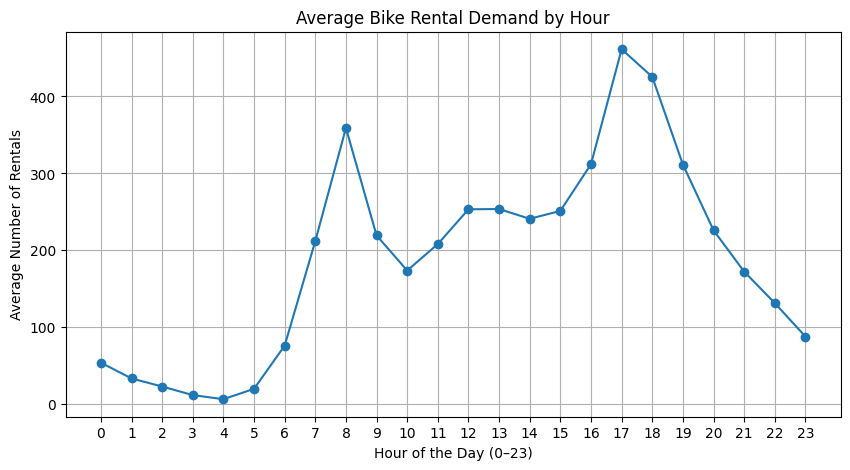

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the original dataset for EDA
df_eda = pd.read_csv("/content/hour.csv")

# Calculate average rentals for each hour
hourly_demand = df_eda.groupby("hr")["cnt"].mean()

# Create the chart
plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour of the Day (0–23)")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True)
plt.show()

weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64


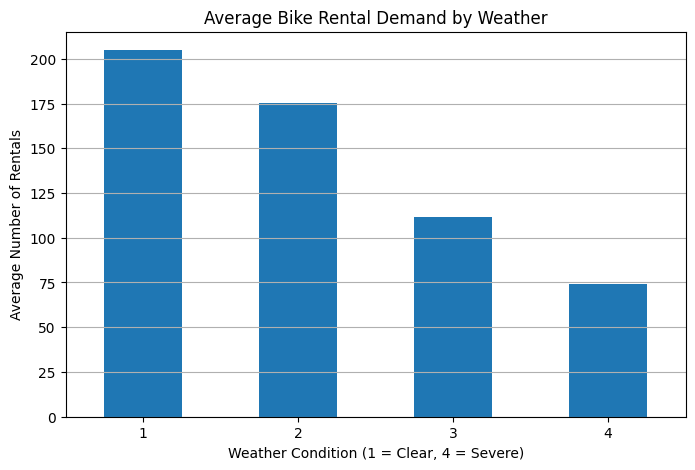

In [13]:
# Average rentals for each weather condition
weather_demand = df_eda.groupby("weathersit")["cnt"].mean()

# Display the values
print(weather_demand)

# Create the chart
plt.figure(figsize=(8, 5))
weather_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand by Weather")
plt.xlabel("Weather Condition (1 = Clear, 4 = Severe)")
plt.ylabel("Average Number of Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

Average rentals by season:
season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64


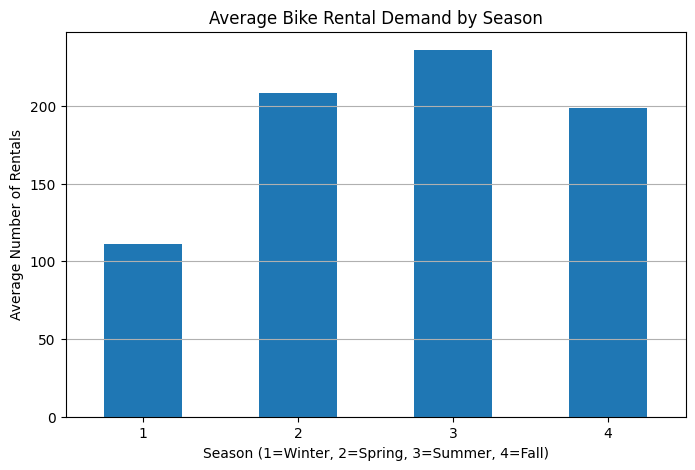

In [14]:
# Calculate average rentals by season
season_demand = df_eda.groupby("season")["cnt"].mean()

print("Average rentals by season:")
print(season_demand)

# Plot the chart
plt.figure(figsize=(8, 5))
season_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand by Season")
plt.xlabel("Season (1=Winter, 2=Spring, 3=Summer, 4=Fall)")
plt.ylabel("Average Number of Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

0 = Non-working day, 1 = Working day
workingday
0    181.405332
1    193.207754
Name: cnt, dtype: float64


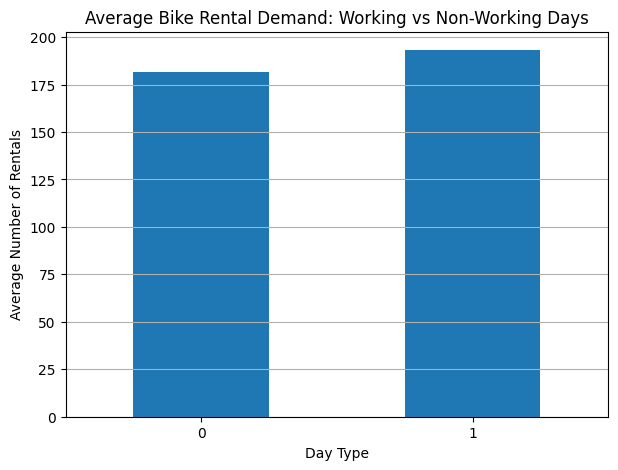

In [15]:
# Average rentals by working-day status
workingday_demand = df_eda.groupby("workingday")["cnt"].mean()

print("0 = Non-working day, 1 = Working day")
print(workingday_demand)

# Create the chart
plt.figure(figsize=(7, 5))
workingday_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand: Working vs Non-Working Days")
plt.xlabel("Day Type")
plt.ylabel("Average Number of Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

Average rentals by weekday:
weekday
0    177.468825
1    183.744655
2    191.238891
3    191.130505
4    196.436665
5    196.135907
6    190.209793
Name: cnt, dtype: float64


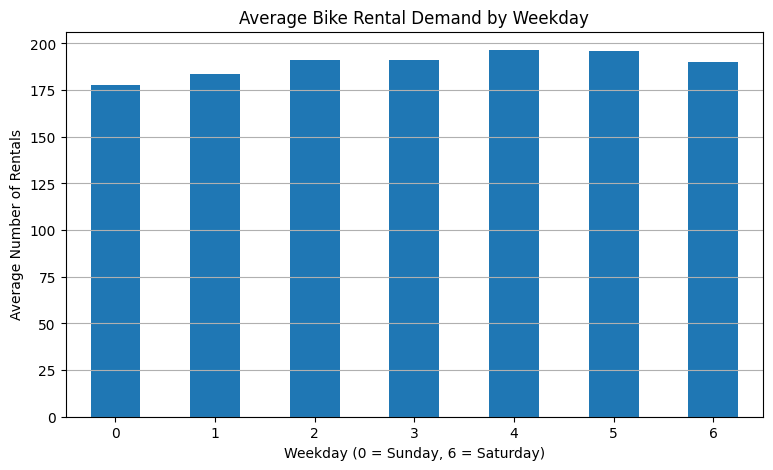

In [16]:
# Average rentals by weekday
weekday_demand = df_eda.groupby("weekday")["cnt"].mean()

print("Average rentals by weekday:")
print(weekday_demand)

# Plot the chart
plt.figure(figsize=(9, 5))
weekday_demand.plot(kind="bar")

plt.title("Average Bike Rental Demand by Weekday")
plt.xlabel("Weekday (0 = Sunday, 6 = Saturday)")
plt.ylabel("Average Number of Rentals")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

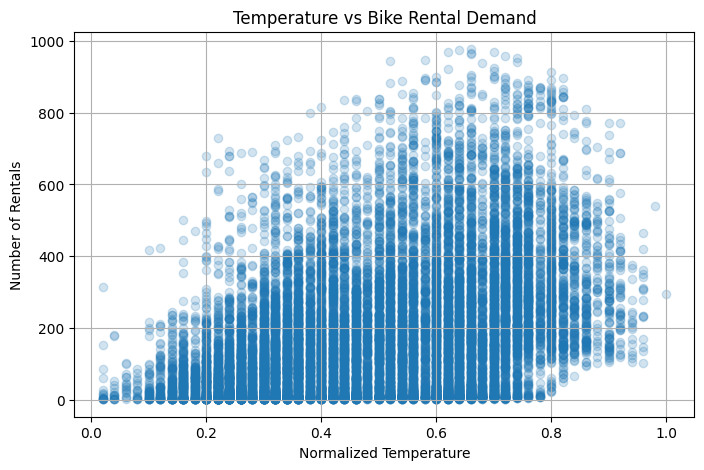

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_eda["temp"],
    df_eda["cnt"],
    alpha=0.2
)

plt.title("Temperature vs Bike Rental Demand")
plt.xlabel("Normalized Temperature")
plt.ylabel("Number of Rentals")
plt.grid(True)
plt.show()

In [18]:
print("PHASE 4: EXPLORATORY DATA ANALYSIS")
print("=" * 45)

print("\n1. Peak rental hour:")
print("Hour:", hourly_demand.idxmax(),
      "| Average rentals:", round(hourly_demand.max(), 2))

print("\n2. Lowest rental hour:")
print("Hour:", hourly_demand.idxmin(),
      "| Average rentals:", round(hourly_demand.min(), 2))

print("\n3. Weather with highest demand:")
print("Weather:", weather_demand.idxmax(),
      "| Average rentals:", round(weather_demand.max(), 2))

print("\n4. Season with highest demand:")
print("Season:", season_demand.idxmax(),
      "| Average rentals:", round(season_demand.max(), 2))

print("\n5. Highest-demand weekday:")
print("Weekday:", weekday_demand.idxmax(),
      "| Average rentals:", round(weekday_demand.max(), 2))

print("\n6. Temperature relationship:")
print("The scatter plot suggests demand generally rises")
print("with temperature, but there is considerable variation.")

PHASE 4: EXPLORATORY DATA ANALYSIS

1. Peak rental hour:
Hour: 17 | Average rentals: 461.45

2. Lowest rental hour:
Hour: 4 | Average rentals: 6.35

3. Weather with highest demand:
Weather: 1 | Average rentals: 204.87

4. Season with highest demand:
Season: 3 | Average rentals: 236.02

5. Highest-demand weekday:
Weekday: 4 | Average rentals: 196.44

6. Temperature relationship:
The scatter plot suggests demand generally rises
with temperature, but there is considerable variation.


In [19]:

print("Model available:", "time_model" in globals())

if "time_model" in globals():
    print("Model type:", type(time_model).__name__)
    print("Expected features:", len(time_model.feature_names_in_))
    print("Feature names:")
    print(list(time_model.feature_names_in_))


Model available: False


In [20]:

print("Cleaned dataset available:", "df_clean" in globals())

if "df_clean" in globals():
    print("Dataset shape:", df_clean.shape)
    print("Columns:", list(df_clean.columns))


Cleaned dataset available: True
Dataset shape: (17379, 21)
Columns: ['yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'atemp', 'hum', 'windspeed', 'cnt', 'day', 'dayofweek', 'season_1', 'season_2', 'season_3', 'season_4', 'weathersit_1', 'weathersit_2', 'weathersit_3', 'weathersit_4']


In [21]:

from sklearn.ensemble import RandomForestRegressor

# Keep the original chronological order
split_index = int(len(df_clean) * 0.8)

train_data = df_clean.iloc[:split_index]
test_data = df_clean.iloc[split_index:]

# Separate input features and target
X_train_time = train_data.drop(columns=["cnt"])
y_train_time = train_data["cnt"]

X_test_time = test_data.drop(columns=["cnt"])
y_test_time = test_data["cnt"]

# Train the model
time_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

time_model.fit(X_train_time, y_train_time)

print("Model trained successfully!")
print("Training rows:", len(X_train_time))
print("Testing rows:", len(X_test_time))
print("Expected input features:", len(time_model.feature_names_in_))


Model trained successfully!
Training rows: 13903
Testing rows: 3476
Expected input features: 20


In [22]:

# Select one example from the test dataset
sample = X_test_time.iloc[[0]]

# Predict bike rental demand
sample_prediction = time_model.predict(sample)[0]

# Show actual and predicted demand
print("Actual bike rentals:", y_test_time.iloc[0])
print("Predicted bike rentals:", round(sample_prediction))


Actual bike rentals: 283
Predicted bike rentals: 281


In [23]:

%pip install gradio -q


In [24]:

import joblib

joblib.dump(time_model, "bike_demand_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [25]:

import gradio as gr
import pandas as pd

def predict_demand(
    year, month, day, hour, weekday,
    workingday, holiday, season, weather,
    temperature, feels_like, humidity, windspeed
):
    # Create all 20 features expected by the model
    values = {
        "yr": int(year),
        "mnth": int(month),
        "hr": int(hour),
        "holiday": int(holiday),
        "weekday": int(weekday),
        "workingday": int(workingday),
        "temp": float(temperature),
        "atemp": float(feels_like),
        "hum": float(humidity),
        "windspeed": float(windspeed),
        "day": int(day),
        "dayofweek": int(weekday),
    }

    # Create season one-hot encoded features
    for i in range(1, 5):
        values[f"season_{i}"] = int(int(season) == i)

    # Create weather one-hot encoded features
    for i in range(1, 5):
        values[f"weathersit_{i}"] = int(int(weather) == i)

    # Match the exact training feature order
    input_df = pd.DataFrame(
        [[values[col] for col in time_model.feature_names_in_]],
        columns=time_model.feature_names_in_
    )

    prediction = max(0, round(float(time_model.predict(input_df)[0])))

    return f"Estimated bike rentals: {prediction}"

demo = gr.Interface(
    fn=predict_demand,
    inputs=[
        gr.Dropdown([0, 1], value=1, label="Year (0 = 2011, 1 = 2012)"),
        gr.Slider(1, 12, value=6, step=1, label="Month"),
        gr.Slider(1, 31, value=15, step=1, label="Day"),
        gr.Slider(0, 23, value=17, step=1, label="Hour"),
        gr.Slider(0, 6, value=2, step=1, label="Weekday (0 = Sunday)"),
        gr.Radio([0, 1], value=1, label="Working day?"),
        gr.Radio([0, 1], value=0, label="Holiday?"),
        gr.Dropdown(
            [1, 2, 3, 4],
            value=2,
            label="Season (1 = Spring, 2 = Summer, 3 = Fall, 4 = Winter)"
        ),
        gr.Dropdown(
            [1, 2, 3, 4],
            value=1,
            label="Weather (1 = Clear, 2 = Mist, 3 = Light rain/snow, 4 = Heavy rain/snow)"
        ),
        gr.Slider(0, 1, value=0.5, step=0.01, label="Temperature (normalized)"),
        gr.Slider(0, 1, value=0.5, step=0.01, label="Feels-like temperature (normalized)"),
        gr.Slider(0, 1, value=0.5, step=0.01, label="Humidity (normalized)"),
        gr.Slider(0, 1, value=0.2, step=0.01, label="Windspeed (normalized)"),
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Bike Rental Demand Predictor",
    description="Enter time and weather conditions to estimate hourly bike rental demand."
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://13861bd9ff54150353.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [26]:

from google.colab import files

files.download("bike_demand_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>